#Лабораторна робота №3. Опукла оболонка
**Виконала:** студентка групи КМ-43 Донкоглова Феофіла  
**Датасет:** `DS0.txt`

**Мова програмування та середовище:** Python 3, Google Colab


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull

In [2]:
file_path = 'DS0.txt'

In [3]:
points = []
with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            points.append([int(parts[0]), int(parts[1])])

points = np.array(points)
print(f"Зчитано точок: {len(points)}")

Зчитано точок: 47128


In [5]:
hull = ConvexHull(points)
hull_points = points[hull.vertices]
print(f"Кількість вершин опуклої оболонки: {len(hull_points)}")

Кількість вершин опуклої оболонки: 29


In [6]:
hull_dataset_path = 'convex_hull_DS0.txt'
with open(hull_dataset_path, 'w', encoding='utf-8') as f:
    for x, y in hull_points:
        f.write(f"{x} {y}\n")

closed_hull = np.vstack([hull_points, hull_points[0]])

def create_canvas(width_px=960, height_px=540, dpi=100):
    fig = plt.figure(figsize=(width_px / dpi, height_px / dpi), dpi=dpi)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, width_px)
    ax.set_ylim(0, height_px)
    ax.axis('off')
    fig.patch.set_facecolor('white')
    return fig, ax

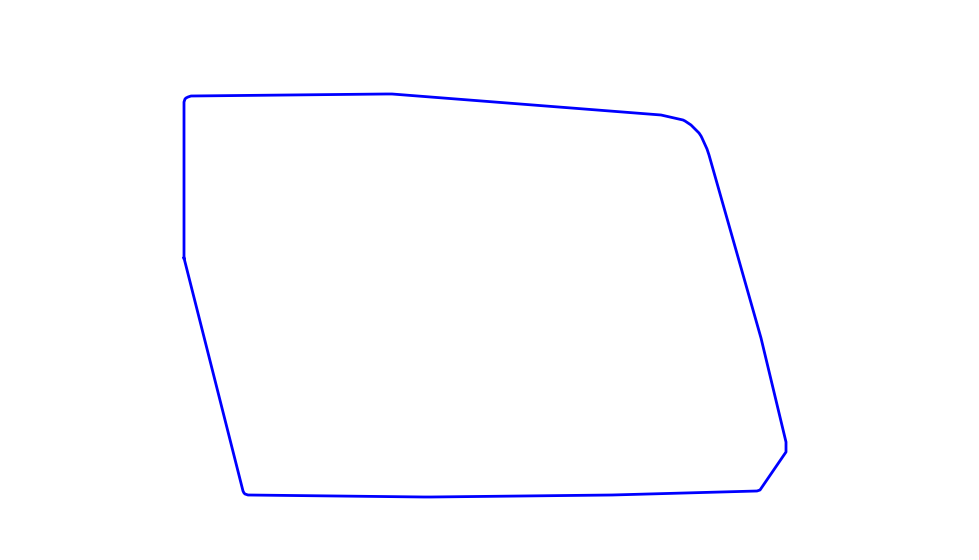

In [11]:
fig1, ax1 = create_canvas()
ax1.plot(closed_hull[:, 0], closed_hull[:, 1], color='blue', linewidth=2)
plt.savefig('hull_only_DS0.png', dpi=100)
plt.show()

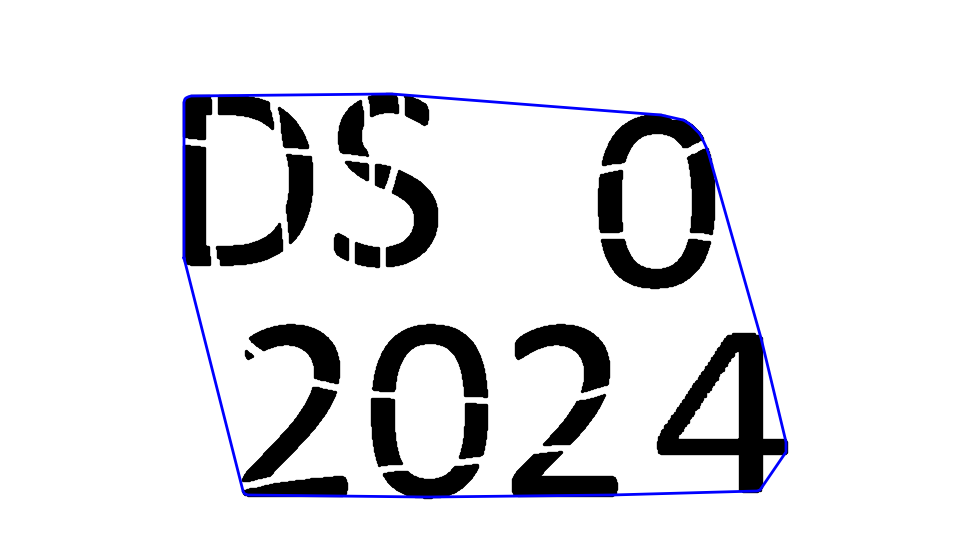

In [10]:
fig2, ax2 = create_canvas()
ax2.scatter(points[:, 0], points[:, 1], s=2, color='black')
ax2.plot(closed_hull[:, 0], closed_hull[:, 1], color='blue', linewidth=2)
plt.savefig('hull_with_points_DS0.png', dpi=100)
plt.show()